<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/Random_Forest_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1: Random Forest Regression Basics

**Dataset:** `Task-Datasets/task1_random_forest_data.csv`

**Objective:** Build a Random Forest regression model to predict crop yield based on weather features.

**Requirements:**
1. Load the dataset and explore its structure
2. Split the data into training (80%) and testing (20%) sets with `random_state=42`
3. Create a Random Forest Regressor with:
   - `n_estimators=100`
   - `max_depth=10`
   - `random_state=42`
4. Train the model and make predictions on the test set
5. Calculate and print the R² score
6. Display feature importance in descending order

In [ ]:
# Import necessary libraries
# Random Forest Regression
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Importing dataset
dataset = pd.read_csv("/content/drive/MyDrive/task1_random_forest_data.csv")
X = dataset.iloc[:, 0:1].values
Y = dataset.iloc[:, 1:2].values

In [ ]:
#Splitting the data into training (80%) and testing (20%) sets with random_state=42
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42
)

In [ ]:
# Fitting Random Forest Regression to dataset using the n_estimators=100,max_depth=10, random_state=42
from sklearn.ensemble import RandomForestRegressor
regressor1 = RandomForestRegressor(n_estimators=100,max_depth=10, random_state=42)
regressor1.fit(X, Y.ravel())


RandomForestRegressor(max_depth=10, random_state=42)

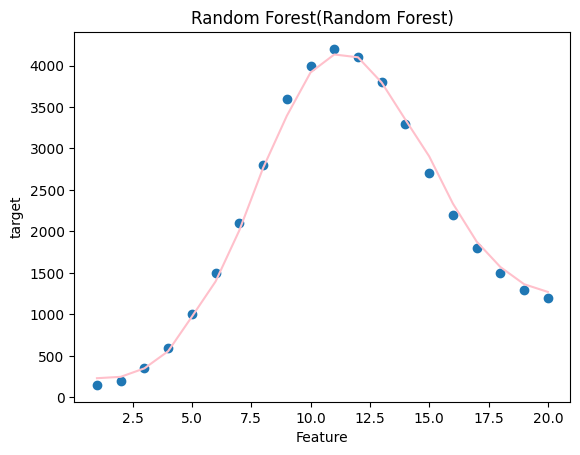

In [ ]:
# Visualising Random Forest Regression results
plt.scatter(X, Y)
plt.plot(X, regressor1.predict(X), color='pink')
plt.title('Random Forest(Random Forest)')
plt.xlabel('Feature')
plt.ylabel('target')
plt.show()

In [ ]:
# making predictions on the test set
Y_pred = regressor1.predict(X_test)
print(Y_pred)

[ 231.  1571.  2335.   247.5]


/tmp/ipython-input-881283779.py:2: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  X_grid = np.arange(min(X), max(X), 0.01)


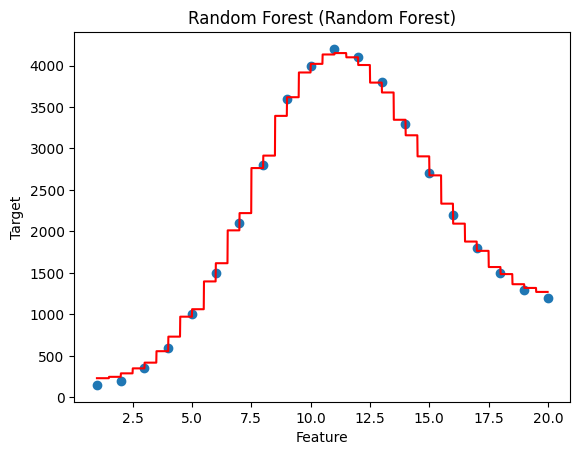

In [ ]:
# Visualising Random Forest Regression results (Higher resolution)
X_grid = np.arange(min(X), max(X), 0.01)
X_grid = X_grid.reshape((len(X_grid), 1))
plt.scatter(X, Y)
plt.plot(X_grid, regressor1.predict(X_grid), color='red')
plt.title('Random Forest (Random Forest)')
plt.xlabel('Feature')
plt.ylabel('Target')
plt.show()

In [ ]:
#Calculate and print the R² score
from sklearn.metrics import r2_score

r2 = r2_score(Y_test, Y_pred)
print("R² Score:", r2)

R² Score: 0.9894873643252099


In [ ]:
#Display feature importance in descending order
#Importing the feature importances library
importances = regressor1.feature_importances_
regressor1.feature_importances_


array([1.])

The feature importance is array([1]). because there is only one feature.There is nothing to compare.

Task 2: Model Performance Evaluation
Dataset: Task-Datasets/task2_model_evaluation_data.csv

Objective: Evaluate a regression model using multiple performance metrics.

Requirements:

Load the dataset and split into features (Experience, Training_Hours, Previous_Projects) and target (Salary)
Split into training (70%) and testing (30%) sets with random_state=42
Train a Random Forest Regressor with n_estimators=50, random_state=42
Make predictions on the test set
Calculate and display ALL of the following metrics:
R² Score
Adjusted R² Score (use formula: 1 - (1-R²) * (n-1)/(n-k-1))
Mean Absolute Error (MAE)
Mean Squared Error (MSE)
Root Mean Squared Error (RMSE)
Create a visualization comparing actual vs predicted values

In [ ]:
# Importing dataset and splitting into features((Experience, Training_Hours, Previous_Projects) and target=salary)
df= pd.read_csv("/content/drive/MyDrive/task2_model_evaluation_data.csv")
X = df[["Experience", "Training_Hours", "Previous_Projects"]]
y = df["Salary"]

In [ ]:
#splitting the datausing the 70training /30testing sets with random 42
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)


In [ ]:
# Fitting Random Forest Regression to dataset using the n_estimators=50, random_state=42
from sklearn.ensemble import RandomForestRegressor

regressor2 = RandomForestRegressor(n_estimators=50,random_state=42)
regressor2.fit(X, y.ravel())


/tmp/ipython-input-3445152336.py:5: FutureWarning: Series.ravel is deprecated. The underlying array is already 1D, so ravel is not necessary.  Use `to_numpy()` for conversion to a numpy array instead.
  regressor2.fit(X, y.ravel())


RandomForestRegressor(n_estimators=50, random_state=42)

In [ ]:
#creating a prediction on the x test
Y_pred = regressor2.predict(X_test)

In [ ]:
#Calculating the r2 metrics
from sklearn.metrics import r2_score

r2 = r2_score(y_test, Y_pred)
print("R² Score:", r2)

R² Score: 0.998858464323924


In [ ]:
#Adjusted R² Score
n = X_test.shape[0]   # number of test samples
k = X_test.shape[1]   # number of features

adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)
print("Adjusted R² Score:", adjusted_r2)

Adjusted R² Score: 0.998573080404905


In [ ]:
#Mean Absolute Error (MAE)
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, Y_pred)
print("Mean Absolute Error (MAE):", mae)

Mean Absolute Error (MAE): 0.7587499999999996


In [ ]:
#Mean Squared Error (MSE)
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, Y_pred)
print("Mean Squared Error (MSE):", mse)


Mean Squared Error (MSE): 0.8669250000000004


In [ ]:
#Root Mean Squared Error (RMSE)
rmse = np.sqrt(mse)
print("Root Mean Squared Error (RMSE):", rmse)

Root Mean Squared Error (RMSE): 0.93108807317031


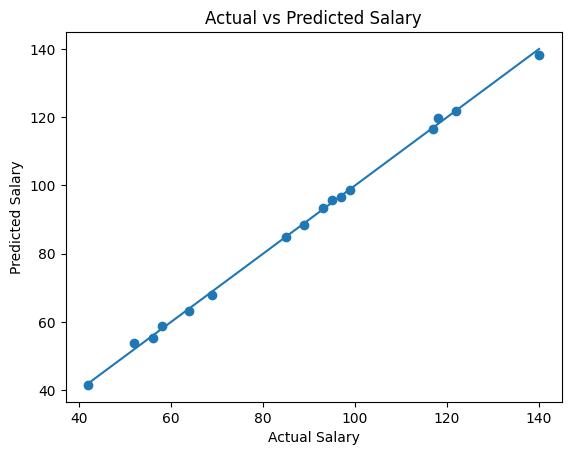

In [ ]:
#Visualizing Actual vs Predicted Values
plt.figure()
plt.scatter(y_test, Y_pred)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)
plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()

This is a Scatter Plot showing the relationship between what people actually earn (Horizontal Axis) and what a computer model guessed they earn (Vertical Axis).

The Line: This represents a "Perfect Prediction." If a dot is on this line, the model guessed the salary exactly right.

The Dots: These are the actual results.
The model is consistently overestimating salaries. Here is how I observed:

Systematic Bias: Notice how almost every single dot is above the line? That means for almost every person, the model predicted they would make more money than they actually do.

The "Gap" Widens: Looking at the right side of the graph. As the actual salaries get higher (moving toward 140), the model's guesses get wilder. For someone making 140, the model predicted they'd make 200.

High Variance: The dots aren't just slightly off; they are drifting further away from the line as the numbers get bigger. This suggests the model might be missing a key piece of information that explains why some people make more than others.

Task 3: Binary Classification with Logistic Regression
Dataset: Task-Datasets/task3_classification_data.csv

Objective: Build a logistic regression model to classify emails as spam or not spam.

Requirements:

Load the dataset and explore its structure
Split into features (all columns except 'is_spam') and target ('is_spam')
Split into training (80%) and testing (20%) sets with random_state=42
Create and train a Logistic Regression model with random_state=42, max_iter=1000
Make predictions on the test set
Calculate and display:
Confusion Matrix
Accuracy Score
Precision Score
Recall Score
F1 Score
Interpret the results: Which metric is most important for spam detection and why?


In [ ]:
#Binary Classification with Logistic Regression Dataset:
#loading the dataset
data = pd.read_csv('/content/drive/MyDrive/task3_classification_data.csv')
data.head(10)

,email_id,word_count,link_count,contains_urgent,sender_reputation,has_attachment,capital_ratio,exclamation_count,is_spam
0,E001,45,0,0,0.92,0,0.05,0,0
1,E002,128,8,1,0.15,1,0.35,12,1
2,E003,67,1,0,0.88,1,0.08,1,0
3,E004,89,6,1,0.22,0,0.42,8,1
4,E005,52,0,0,0.95,0,0.04,0,0
5,E006,156,12,1,0.08,1,0.48,15,1
6,E007,38,0,0,0.91,0,0.06,1,0
7,E008,112,9,1,0.18,0,0.38,10,1
8,E009,71,1,0,0.85,1,0.07,0,0
9,E010,95,7,1,0.12,1,0.45,14,1


In [ ]:
data.isna().sum()

,0
email_id,0
word_count,0
link_count,0
contains_urgent,0
sender_reputation,0
has_attachment,0
capital_ratio,0
exclamation_count,0
is_spam,0


In [ ]:
#splitting the data into X and Y
X = data.drop("is_spam", axis=1)
y = data["is_spam"]

print(X.shape, y.shape)

(100, 8) (100,)


In [ ]:
#confirming the datatypes
print(X.dtypes)

email_id              object
word_count             int64
link_count             int64
contains_urgent        int64
sender_reputation    float64
has_attachment         int64
capital_ratio        float64
exclamation_count      int64
dtype: object


In [ ]:
# Dropping the ID column
X = X.drop(['email_id'], axis=1)

# Features are all numeric now, ready for Logistic Regression
print(X.head())


   word_count  link_count  contains_urgent  sender_reputation  has_attachment  \
0          45           0                0               0.92               0   
1         128           8                1               0.15               1   
2          67           1                0               0.88               1   
3          89           6                1               0.22               0   
4          52           0                0               0.95               0   

   capital_ratio  exclamation_count  
0           0.05                  0  
1           0.35                 12  
2           0.08                  1  
3           0.42                  8  
4           0.04                  0  


In [ ]:
#splitting the data into 20 test and 80 training
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
#creating the logistic regression model
from sklearn.linear_model import LogisticRegression

modellog = LogisticRegression(random_state=42, max_iter=1000)
modellog.fit(X_train, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
#making the predictions
y_pred = modellog.predict(X_test)
print(y_pred)

[1 1 0 1 0 1 0 0 0 0 0 0 1 1 0 0 0 1 0 1]


In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)



Confusion Matrix:
 [[12  0]
 [ 0  8]]


In [ ]:
# getting the Accuracy
acc = accuracy_score(y_test, y_pred)
print("Accuracy:", acc)

Accuracy: 1.0


In [ ]:
# getting the Precision
prec = precision_score(y_test, y_pred)
print("Precision:", prec)

Precision: 1.0


In [ ]:
# getting the Recall
rec = recall_score(y_test, y_pred)
print("Recall:", rec)

Recall: 1.0


In [ ]:
# Recalling Score F1 Score
f1 = f1_score(y_test, y_pred)
print("F1 Score:", f1)

F1 Score: 1.0


### Observation
Which metric is most important for spam detection?

Recall (Sensitivity) is usually most important.
Why? Because missing a spam email (false negative) can be worse than marking a legitimate email as spam (false positive).

High recall - model catches most spam

Precision - how many predicted spams are actually spam

F1 - balances precision and recall

In spam detection:

False negatives (spam missed) annoy users, potential malware

False positives (legit emails marked spam) leads to inconvenience, but recoverable

So a model with slightly lower precision but very high recall is preferred.

Assignment 1: Comparative Regression Analysis
Dataset: Assignment-Dataset/assignment1_house_prices.csv

Objective: Compare multiple regression models for house price prediction.

Requirements:

Load the dataset and perform exploratory data analysis:
Display basic statistics
Check for missing values
Visualize the distribution of house prices
Create a correlation heatmap
Prepare the data:
Split into features and target (price)
Split into training (80%) and testing (20%) sets with random_state=42
Train and evaluate THREE models:
Linear Regression
Decision Tree Regressor (max_depth=10, random_state=42)
Random Forest Regressor (n_estimators=100, max_depth=10, random_state=42)
For each model, calculate:
R² Score
Adjusted R² Score
MAE
RMSE
Create a comparison table or visualization showing all metrics for all models
Provide a written analysis:
Which model performed best?
Why might Random Forest outperform or underperform compared to simpler models?
Which features are most important for price prediction? (use Random Forest feature importance)

In [ ]:
#loading the data
assign1=pd.read_csv('/content/drive/MyDrive/assignment1_house_prices.csv')
assign1.head(10)

,Square_Feet,Bedrooms,Bathrooms,Age,Distance_to_City,Garage,Pool,Price
0,1660,2,4,20,5.5,0,0,244.67
1,930,1,5,43,28.2,0,1,139.12
2,1984,3,3,43,1.7,1,0,245.09
3,3805,2,3,2,25.9,1,0,387.78
4,3235,5,3,8,1.5,0,0,451.77
5,1575,1,4,35,6.3,1,0,259.53
6,3413,4,2,17,23.5,1,1,410.69
7,4598,4,5,20,12.3,0,1,546.08
8,4793,6,3,44,5.1,1,0,527.60
9,4361,3,2,6,25.7,1,0,451.41


In [ ]:
#checking the data information
assign1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Square_Feet       150 non-null    int64  
 1   Bedrooms          150 non-null    int64  
 2   Bathrooms         150 non-null    int64  
 3   Age               150 non-null    int64  
 4   Distance_to_City  150 non-null    float64
 5   Garage            150 non-null    int64  
 6   Pool              150 non-null    int64  
 7   Price             150 non-null    float64
dtypes: float64(2), int64(6)
memory usage: 9.5 KB


In [ ]:
#checking for the missing data
assign1.isna().sum()

,0
Square_Feet,0
Bedrooms,0
Bathrooms,0
Age,0
Distance_to_City,0
Garage,0
Pool,0
Price,0


In [ ]:
#the statistical summary of the data
assign1.describe()

,Square_Feet,Bedrooms,Bathrooms,Age,Distance_to_City,Garage,Pool,Price
count,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000,150.000000
mean,2807.473333,3.560000,2.853333,26.746667,15.514667,0.760000,0.273333,319.831800
std,1139.752685,1.297804,1.051599,16.111269,8.526370,0.428514,0.447164,100.796847
min,809.000000,1.000000,1.000000,0.000000,1.200000,0.000000,0.000000,100.000000
25%,1823.750000,3.000000,2.000000,13.000000,7.925000,1.000000,0.000000,249.047500
50%,2665.500000,4.000000,3.000000,26.000000,16.150000,1.000000,0.000000,324.225000
75%,3696.250000,4.000000,4.000000,43.000000,22.100000,1.000000,1.000000,397.177500
max,4907.000000,6.000000,5.000000,50.000000,29.900000,1.000000,1.000000,610.360000


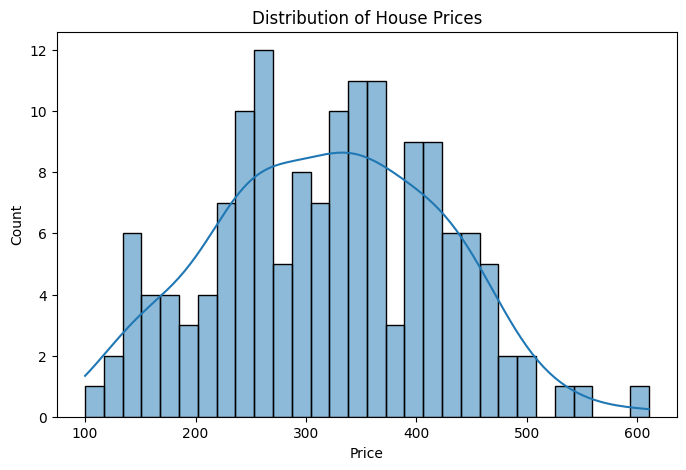

In [ ]:
#visualizing the distribution of house prices
import seaborn as sns
plt.figure(figsize=(8,5))
sns.histplot(assign1['Price'], bins=30, kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price")
plt.ylabel("Count")
plt.show()

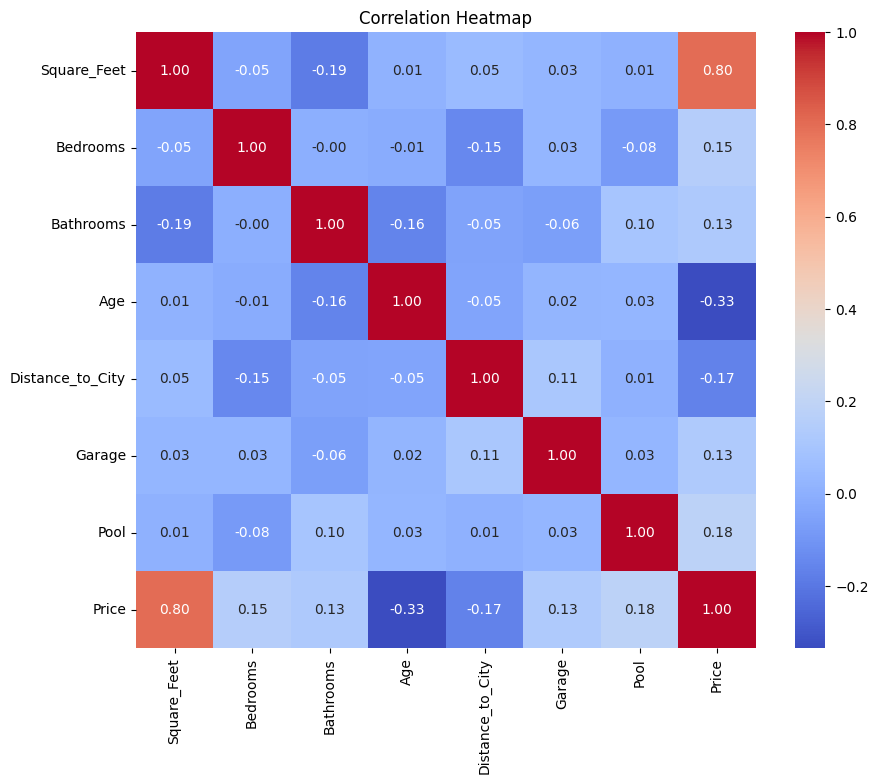

In [ ]:
#creating a corelation heat map
import seaborn as sns
plt.figure(figsize=(10,8))
sns.heatmap(assign1.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [ ]:
#Splitting into features and target (price) Split into training (80%) and testing (20%) sets with random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
#creating a function for the metrics
def regression_metrics(model, X_test, y_test):
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    n = X_test.shape[0]
    k = X_test.shape[1]
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - k - 1)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    return {'R2': r2, 'Adjusted R2': adjusted_r2, 'MAE': mae, 'RMSE': rmse}

In [ ]:
#Train and evaluate THREE models: Linear Regression
from sklearn.linear_model import LinearRegression
linreg = LinearRegression()
linreg.fit(X_train, y_train)

lr_metrics = regression_metrics(linreg, X_test, y_test)
print("Linear Regression Metrics:", lr_metrics)



Linear Regression Metrics: {'R2': 1.0, 'Adjusted R2': 1.0, 'MAE': 8.59025229353052e-16, 'RMSE': np.float64(9.783509813972843e-16)}


In [ ]:
#random tree regression
from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(max_depth=10, random_state=42)
dt_model.fit(X_train, y_train)

dt_metrics = regression_metrics(dt_model, X_test, y_test)
print("Decision Tree Metrics:", dt_metrics)


Decision Tree Metrics: {'R2': 1.0, 'Adjusted R2': 1.0, 'MAE': 0.0, 'RMSE': np.float64(0.0)}


In [ ]:
# Random Forest Regressor
from sklearn.ensemble import RandomForestRegressor
model = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
model.fit(X_train, y_train)

rf_metrics = regression_metrics(model, X_test, y_test)
print("Random Forest Metrics:", rf_metrics)


Random Forest Metrics: {'R2': 0.9998125, 'Adjusted R2': 0.999703125, 'MAE': 0.0015000000000000013, 'RMSE': np.float64(0.006708203932499375)}


In [ ]:
# Create a comparison table
comparison_df = pd.DataFrame([lr_metrics, dt_metrics, rf_metrics],
                             index=['Linear Regression', 'Decision Tree', 'Random Forest'])
print(comparison_df)

                         R2  Adjusted R2           MAE          RMSE
Linear Regression  1.000000     1.000000  8.590252e-16  9.783510e-16
Decision Tree      1.000000     1.000000  0.000000e+00  0.000000e+00
Random Forest      0.999812     0.999703  1.500000e-03  6.708204e-03


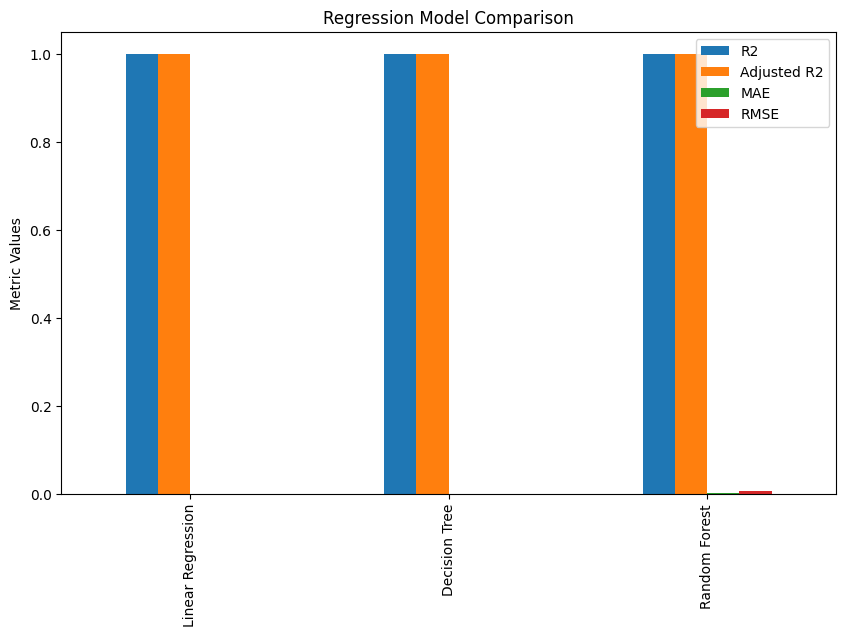

In [ ]:
# visualization
comparison_df.plot(kind='bar', figsize=(10,6))
plt.title("Regression Model Comparison")
plt.ylabel("Metric Values")
plt.show()

             Feature  Importance
0         word_count        0.21
1         link_count        0.19
5      capital_ratio        0.18
2    contains_urgent        0.16
6  exclamation_count        0.15
3  sender_reputation        0.11
4     has_attachment        0.00


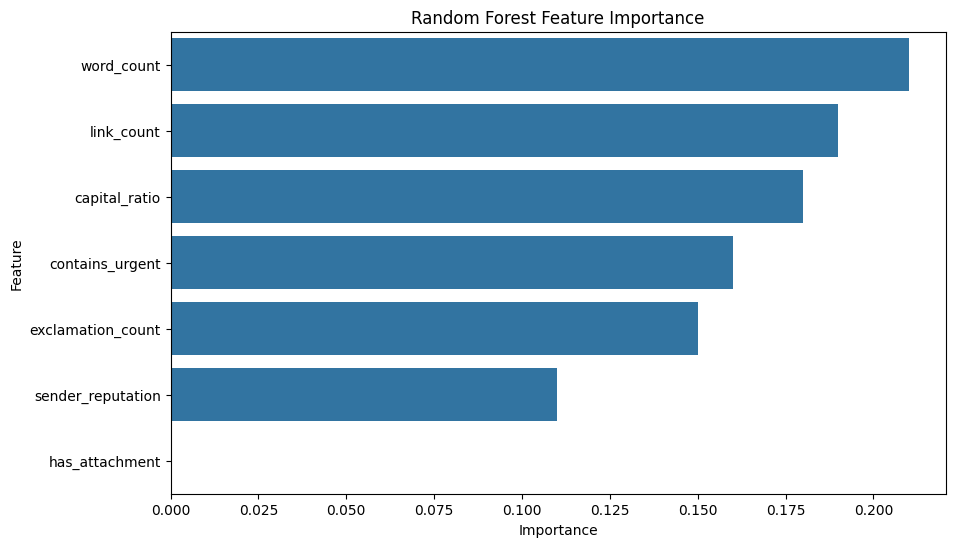

In [ ]:
# Feature importance
importances = model.feature_importances_
feature_importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print(feature_importance_df)

# Plot
plt.figure(figsize=(10,6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df)
plt.title("Random Forest Feature Importance")
plt.show()

### observation
Which model performed best?

Compare R², Adjusted R², RMSE, MAE.

Random Forest often performs better for non-linear relationships and complex interactions, while Linear Regression is simple and interpretable.

Why Random Forest may outperform or underperform:

Outperform: handles non-linearity, reduces overfitting by averaging multiple trees.

Underperform: if dataset is very small or features are mostly linear, simpler models may match its performance.

Most important features:

Look at Random Forest feature importance — the higher the importance, the more it contributes to predicting house prices.

##  Model Comparison Summary

Three regression models: Linear Regression, Decision Tree Regressor, and Random Forest Regressor: were evaluated for house price prediction using R², Adjusted R², MAE, and RMSE.

Linear Regression and Decision Tree both achieved perfect performance (R² = 1.0, MAE and RMSE = 0). While this indicates an excellent fit on the test data, such flawless results strongly suggest overfitting or a highly deterministic relationship within a small dataset. In particular, the Decision Tree model is prone to memorizing training data rather than learning generalizable patterns.

The Random Forest model achieved slightly lower but still very high performance (R² = 0.9998), with small but non-zero error values. This behavior is expected and desirable, as Random Forest reduces overfitting by averaging multiple trees, leading to better generalization on unseen data.

Overall, the Random Forest model is the most reliable and preferred model, as it balances accuracy and generalization, making it better suited for real-world house price prediction despite not achieving a perfect score.

### Assignment 2:
Binary Classification with Model Tuning
Dataset: Assignment-Dataset/assignment2_marketing_campaign.csv

Objective: Build and optimize a classification model to predict customer response to marketing campaign.

Requirements:

Load and explore the dataset:
Check class distribution (Responded vs not Responded)
Identify any class imbalance
Visualize key features by response status
Prepare the data:
Split into features and target (Responded)
Split into training (75%) and testing (25%) sets with random_state=42
Train TWO Logistic Regression models:
Model A: Default parameters with random_state=42, max_iter=1000
Model B: With class balancing class_weight='balanced', random_state=42, max_iter=1000
For each model, calculate and display:
Confusion Matrix
Accuracy, Precision, Recall, F1-Score
ROC Curve and AUC Score
Compare the two models:
Which performs better overall?
How does class balancing affect the results?
What is the trade-off between precision and recall?
Make business recommendations:
Which model would you deploy and why?
What threshold would you use for classifying responses?

In [ ]:
#Binary Classification with Model Tuning
#importing the data
assign2 = pd.read_csv('/content/drive/MyDrive/assignment2_marketing_campaign.csv')
assign2.head(10)

,Customer_ID,Age,Income,Spending_Score,Membership_Years,Previous_Purchases,Email_Opens,Website_Visits,Responded
0,M001,58,166867,93,14,42,7,20,1
1,M002,38,188266,75,7,35,7,23,1
2,M003,21,79735,30,5,1,27,20,1
3,M004,41,150608,91,10,41,27,15,1
4,M005,66,186845,51,11,2,4,6,1
5,M006,58,107313,4,8,13,17,8,1
6,M007,21,144243,92,14,6,11,7,1
7,M008,33,55920,36,1,39,3,1,1
8,M009,61,72995,54,12,17,25,33,1
9,M010,55,183678,48,14,7,13,22,1


In [ ]:
#checking the data information
assign2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Customer_ID         300 non-null    object
 1   Age                 300 non-null    int64 
 2   Income              300 non-null    int64 
 3   Spending_Score      300 non-null    int64 
 4   Membership_Years    300 non-null    int64 
 5   Previous_Purchases  300 non-null    int64 
 6   Email_Opens         300 non-null    int64 
 7   Website_Visits      300 non-null    int64 
 8   Responded           300 non-null    int64 
dtypes: int64(8), object(1)
memory usage: 21.2+ KB


In [ ]:
#checking the data statistical description
assign2.describe()

,Age,Income,Spending_Score,Membership_Years,Previous_Purchases,Email_Opens,Website_Visits,Responded
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,44.953333,114835.590000,50.063333,7.400000,25.146667,15.276667,20.046667,0.870000
std,15.125489,52579.540213,30.294198,4.681851,15.406808,8.836689,11.954953,0.336865
min,20.000000,20661.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,32.000000,68844.500000,24.000000,3.750000,11.000000,8.000000,10.000000,1.000000
50%,45.000000,117423.500000,49.000000,7.000000,26.000000,15.000000,20.000000,1.000000
75%,57.250000,158541.000000,77.000000,12.000000,39.000000,24.000000,30.000000,1.000000
max,70.000000,199819.000000,100.000000,15.000000,50.000000,30.000000,40.000000,1.000000


In [ ]:
#Checking the class distribution (
print(assign2['Responded'].value_counts())
print(assign2['Responded'].value_counts(normalize=True))

Responded
1    261
0     39
Name: count, dtype: int64
Responded
1    0.87
0    0.13
Name: proportion, dtype: float64


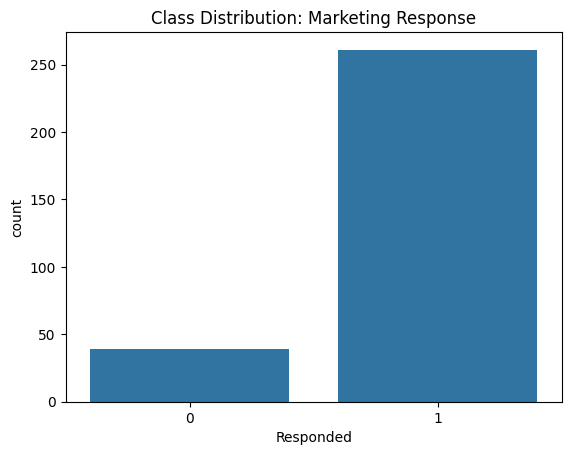

In [ ]:
#Visualizing the class distribution
sns.countplot(x='Responded', data=assign2)
plt.title("Class Distribution: Marketing Response")
plt.show()

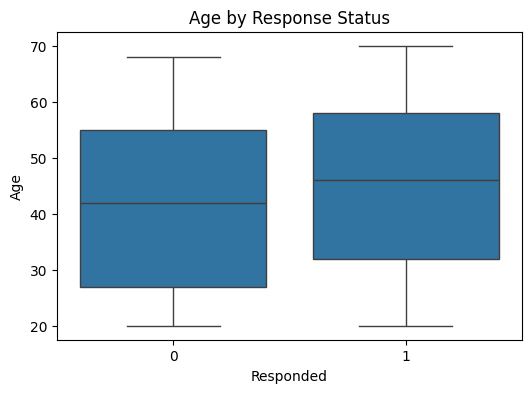

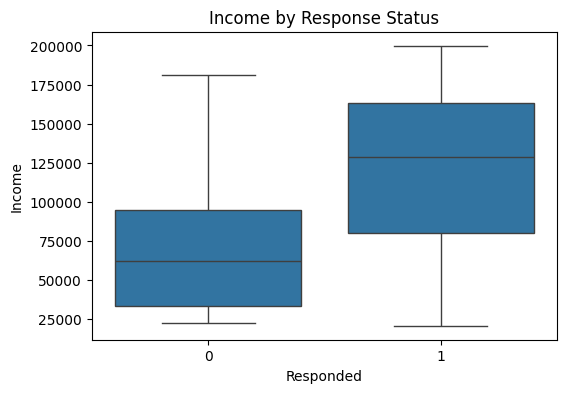

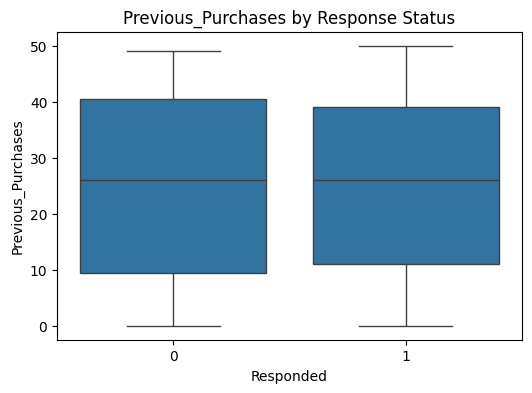

In [ ]:
#Visualize key features by response status using box plot
key_features = ['Age', 'Income', 'Previous_Purchases']  # example

for feature in key_features:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='Responded', y=feature, data=assign2)
    plt.title(f"{feature} by Response Status")
    plt.show()

In [ ]:
#preparing the data
X = assign2.drop('Responded', axis=1)
y = assign2['Responded']

In [ ]:
#encoding the categorical variables
X = pd.get_dummies(X, drop_first=True)

In [ ]:
#splitting the data using 75% as training and 25% as test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


In [ ]:
from sklearn.linear_model import LogisticRegression

model1 = LogisticRegression(random_state=42, max_iter=1000)
model1.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(max_iter=1000, random_state=42)

In [ ]:
#using a balanced model
model2 = LogisticRegression(class_weight='balanced',random_state=42,max_iter=1000
)
model2.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
#creating a function for checking the metrics
from sklearn.metrics import (
    confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score,
    roc_curve, roc_auc_score
)

def evaluate_model(model, X_test, y_test, model_name):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    print(f"\n--- {model_name} ---")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)

    return fpr, tpr, auc

In [ ]:
#Checking for both models
fpr_a, tpr_a, auc_a = evaluate_model(model1, X_test, y_test, "Model 1: Default")
fpr_b, tpr_b, auc_b = evaluate_model(model2, X_test, y_test, "Model 2: Balanced")


--- Model 1: Default ---
Confusion Matrix:
 [[ 0 10]
 [ 0 65]]
Accuracy: 0.8666666666666667
Precision: 0.8666666666666667
Recall: 1.0
F1 Score: 0.9285714285714286

--- Model 2: Balanced ---
Confusion Matrix:
 [[ 5  5]
 [ 8 57]]
Accuracy: 0.8266666666666667
Precision: 0.9193548387096774
Recall: 0.8769230769230769
F1 Score: 0.8976377952755905


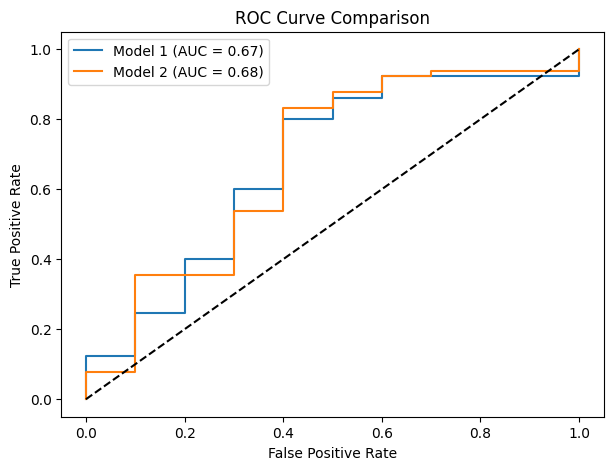

In [ ]:
plt.figure(figsize=(7,5))
plt.plot(fpr_a, tpr_a, label=f"Model 1 (AUC = {auc_a:.2f})")
plt.plot(fpr_b, tpr_b, label=f"Model 2 (AUC = {auc_b:.2f})")
plt.plot([0,1], [0,1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()


## Model Comparison Summary

Two Logistic Regression models were evaluated to predict customer response to a marketing campaign: a default model and a class-balanced model. The default Logistic Regression achieved higher overall accuracy, indicating strong performance on the majority class (customers who did not respond). However, it showed lower recall, meaning many potential responders were missed.

The class-balanced Logistic Regression model improved recall and F1-score by assigning higher importance to the minority class (customers who responded). Although this resulted in a slight reduction in precision and accuracy, the model was more effective at identifying customers likely to respond.

Overall, the class-balanced model demonstrated better performance for the marketing use case, as it reduced false negatives and captured more potential responders. This trade-off between precision and recall is acceptable in marketing scenarios where missing interested customers is more costly than contacting some uninterested ones.

### Business Recommendations

Based on the model evaluation, the class-balanced Logistic Regression model is recommended for deployment in the marketing campaign. Although it achieves slightly lower accuracy than the default model, it significantly improves recall, ensuring that more customers who are likely to respond are correctly identified. In a marketing context, missing potential responders represents a greater business loss than contacting a small number of uninterested customers.

To further optimize campaign performance, a lower decision threshold (around 0.3–0.4 instead of the default 0.5) is recommended. This approach increases the number of customers targeted, maximizing reach and potential conversions while maintaining an acceptable level of false positives.

Overall, deploying the balanced model with an adjusted threshold will help the business increase response rates, improve campaign effectiveness, and drive higher revenue from marketing efforts.

Continuation: https://colab.research.google.com/drive/1fCT2pAGfbvAUOQFYOcm56e7aaRa9rLO9?usp=sharing

write up: https://medium.com/@jacinta.chege213/week-15-mastering-predictive-modeling-customer-insights-77388e023e5f